In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16, InceptionV3
import librosa
import librosa.display
import cv2

# 设置随机种子
tf.random.set_seed(42)
np.random.seed(42)

# 设置数据集路径（根据你的Kaggle环境调整）
dataset_path = "/kaggle/input/ravdess-emotional-speech-audio/"

2025-10-23 04:28:36.776049: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761193717.066158      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761193717.147091      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
def parse_ravdess_filename(filename):
    """解析RAVDESS文件名"""
    parts = filename.split('-')
    emotion_code = int(parts[2])
    
    emotion_map = {
        1: 'neutral', 2: 'calm', 3: 'happy', 4: 'sad',
        5: 'angry', 6: 'fearful', 7: 'disgust', 8: 'surprised'
    }
    
    return emotion_map.get(emotion_code, 'unknown')

def load_ravdess_data(dataset_path):
    """加载RAVDESS数据集"""
    audio_files = []
    labels = []
    
    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            if file.endswith('.wav'):
                file_path = os.path.join(root, file)
                emotion = parse_ravdess_filename(file)
                
                if emotion != 'unknown':
                    audio_files.append(file_path)
                    labels.append(emotion)
    
    return audio_files, labels

def audio_to_mel_spectrogram(audio_path, target_size=(224, 224)):
    """将音频转换为Mel频谱图"""
    try:
        y, sr = librosa.load(audio_path, sr=None)
        
        mel_spect = librosa.feature.melspectrogram(
            y=y, sr=sr, n_mels=128, fmax=8000
        )
        
        log_mel_spect = librosa.power_to_db(mel_spect, ref=np.max)
        log_mel_spect_resized = cv2.resize(log_mel_spect, target_size)
        
        # 归一化
        log_mel_spect_normalized = (log_mel_spect_resized - log_mel_spect_resized.min()) / (
            log_mel_spect_resized.max() - log_mel_spect_resized.min() + 1e-8
        )
        
        return log_mel_spect_normalized
    
    except Exception as e:
        print(f"Error processing {audio_path}: {str(e)}")
        return None

def prepare_dataset(audio_files, labels, target_size=(224, 224)):
    """准备数据集"""
    X = []
    y_processed = []
    
    emotion_to_idx = {
        'neutral': 0, 'calm': 1, 'happy': 2, 'sad': 3,
        'angry': 4, 'fearful': 5, 'disgust': 6, 'surprised': 7
    }
    
    print("Converting audio files to Mel spectrograms...")
    for i, (audio_path, emotion) in enumerate(zip(audio_files, labels)):
        if i % 100 == 0:
            print(f"Processed {i}/{len(audio_files)} files")
        
        mel_spect = audio_to_mel_spectrogram(audio_path, target_size)
        if mel_spect is not None:
            mel_spect = np.expand_dims(mel_spect, axis=-1)
            X.append(mel_spect)
            y_processed.append(emotion_to_idx[emotion])
    
    return np.array(X), np.array(y_processed)

In [3]:
def create_cnn_x_model(input_shape=(224, 224, 1), num_classes=8):
    """论文提出的CNN-X模型"""
    model = keras.Sequential([
        # 第一个卷积块
        layers.Conv2D(8, (3, 3), activation='relu', padding='same', 
                      input_shape=input_shape, name='conv1'),
        layers.AveragePooling2D((2, 2), name='pool1'),
        
        # 第二个卷积块
        layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='conv2'),
        layers.AveragePooling2D((2, 2), name='pool2'),
        
        # 第三个卷积块
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv3'),
        layers.AveragePooling2D((2, 2), name='pool3'),
        
        # 展平层
        layers.Flatten(),
        
        # 全连接层
        layers.Dense(2048, activation='relu', name='fc1'),
        layers.Dense(2048, activation='relu', name='fc2'),
        layers.Dense(num_classes, activation='softmax', name='output')
    ])
    
    return model

def create_vgg16_model(input_shape=(224, 224, 3), num_classes=8):
    """VGG-16模型 - 修复版本（使用3通道输入）"""
    # 直接使用3通道输入
    inputs = keras.Input(shape=input_shape)
    
    # 使用预训练的VGG16
    base_model = VGG16(weights='imagenet', include_top=False, input_tensor=inputs)
    base_model.trainable = False  # 冻结预训练权重
    
    # 添加自定义分类器
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = keras.Model(inputs, outputs)
    return model

def create_inceptionv3_model(input_shape=(224, 224, 3), num_classes=8):
    """InceptionV3模型 - 修复版本（使用3通道输入）"""
    # 直接使用3通道输入
    inputs = keras.Input(shape=input_shape)
    
    # 使用预训练的InceptionV3
    base_model = InceptionV3(weights='imagenet', include_top=False, input_tensor=inputs)
    base_model.trainable = False  # 冻结预训练权重
    
    # 添加自定义分类器
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = keras.Model(inputs, outputs)
    return model

def convert_to_3channels(X):
    """将单通道图像转换为3通道（通过复制通道）"""
    return np.repeat(X, 3, axis=-1)

def create_mlp_model(input_shape=(224, 224, 1), num_classes=8):
    """MLP模型（论文中的数值方法基准）"""
    model = keras.Sequential([
        layers.Flatten(input_shape=input_shape),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [4]:
# 加载数据
print("Loading RAVDESS dataset...")
audio_files, labels = load_ravdess_data(dataset_path)

print(f"Total audio files: {len(audio_files)}")
print("Emotion distribution:")
print(pd.Series(labels).value_counts())

# 准备单通道数据（用于CNN-X和MLP）
print("Preparing single-channel dataset...")
X, y = prepare_dataset(audio_files, labels)

# 准备3通道数据（用于VGG16和InceptionV3）
print("Converting to 3 channels for VGG16 and InceptionV3...")
X_3ch = convert_to_3channels(X)

# 划分单通道数据集
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.66, random_state=42, stratify=y_temp
)

# 划分3通道数据集（保持相同的索引）
X_train_3ch, X_temp_3ch, y_train_3ch, y_temp_3ch = train_test_split(
    X_3ch, y, test_size=0.3, random_state=42, stratify=y
)
X_val_3ch, X_test_3ch, y_val_3ch, y_test_3ch = train_test_split(
    X_temp_3ch, y_temp_3ch, test_size=0.66, random_state=42, stratify=y_temp_3ch
)

print(f"Single-channel - Training: {X_train.shape}, Test: {X_test.shape}")
print(f"3-channel - Training: {X_train_3ch.shape}, Test: {X_test_3ch.shape}")

Loading RAVDESS dataset...
Total audio files: 2880
Emotion distribution:
surprised    384
disgust      384
fearful      384
sad          384
calm         384
happy        384
angry        384
neutral      192
Name: count, dtype: int64
Preparing single-channel dataset...
Converting audio files to Mel spectrograms...
Processed 0/2880 files
Processed 100/2880 files
Processed 200/2880 files
Processed 300/2880 files
Processed 400/2880 files
Processed 500/2880 files
Processed 600/2880 files
Processed 700/2880 files
Processed 800/2880 files
Processed 900/2880 files
Processed 1000/2880 files
Processed 1100/2880 files
Processed 1200/2880 files
Processed 1300/2880 files
Processed 1400/2880 files
Processed 1500/2880 files
Processed 1600/2880 files
Processed 1700/2880 files
Processed 1800/2880 files
Processed 1900/2880 files
Processed 2000/2880 files
Processed 2100/2880 files
Processed 2200/2880 files
Processed 2300/2880 files
Processed 2400/2880 files
Processed 2500/2880 files
Processed 2600/2880

In [5]:
def train_and_evaluate_model(model, model_name, X_train, y_train, X_val, y_val, X_test, y_test, epochs=20):
    """训练和评估单个模型"""
    print(f"\n{'='*50}")
    print(f"Training {model_name}")
    print(f"{'='*50}")
    
    # 编译模型
    model.compile(
        optimizer=keras.optimizers.RMSprop(
            learning_rate=0.001,  # 学习率
            momentum=0.8,         # 动量 - 论文中提到的参数
            rho=0.9               # RMSprop的rho参数
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # 回调函数
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=5,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7
        )
    ]
    
    # 训练模型
    history = model.fit(
        X_train, y_train,
        batch_size=32,
        epochs=epochs,
        validation_data=(X_val, y_val),
        callbacks=callbacks,
        verbose=1
    )
    
    # 评估模型
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    
    # 预测
    y_pred = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    
    # 计算其他指标
    from sklearn.metrics import precision_score, recall_score, f1_score
    precision = precision_score(y_test, y_pred_classes, average='weighted')
    recall = recall_score(y_test, y_pred_classes, average='weighted')
    f1 = f1_score(y_test, y_pred_classes, average='weighted')
    
    print(f"\n{model_name} Results:")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    
    return {
        'model_name': model_name,
        'model': model,
        'history': history,
        'test_accuracy': test_accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'y_pred': y_pred_classes
    }

In [6]:
# 创建所有模型
models_single_ch = {
    'CNN-X (Proposed)': create_cnn_x_model(input_shape=(224, 224, 1)),
    'MLP': create_mlp_model(input_shape=(224, 224, 1))
}

models_3ch = {
    'VGG-16': create_vgg16_model(input_shape=(224, 224, 3)),
    'InceptionV3': create_inceptionv3_model(input_shape=(224, 224, 3))
}

# 存储所有结果
results = {}

print("Training single-channel models...")
# 训练单通道模型
for name, model in models_single_ch.items():
    try:
        result = train_and_evaluate_model(
            model, name, X_train, y_train, X_val, y_val, X_test, y_test, epochs=20
        )
        results[name] = result
    except Exception as e:
        print(f"Error training {name}: {str(e)}")
        continue

print("\nTraining 3-channel models...")
# 训练3通道模型
for name, model in models_3ch.items():
    try:
        result = train_and_evaluate_model(
            model, name, X_train_3ch, y_train, X_val_3ch, y_val, X_test_3ch, y_test, epochs=20
        )
        results[name] = result
    except Exception as e:
        print(f"Error training {name}: {str(e)}")
        continue

print(f"\nSuccessfully trained {len(results)} out of 4 models")

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-10-23 04:31:09.713806: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Training single-channel models...

Training CNN-X (Proposed)
Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.1349 - loss: 2.3818 - val_accuracy: 0.2218 - val_loss: 1.8886 - learning_rate: 0.0010
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.2492 - loss: 1.8648 - val_accuracy: 0.3413 - val_loss: 1.6556 - learning_rate: 0.0010
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.3872 - loss: 1.6323 - val_accuracy: 0.4710 - val_loss: 1.4975 - learning_rate: 0.0010
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.4529 - loss: 1.4288 - val_accuracy: 0.4949 - val_loss: 1.3227 - learning_rate: 0.0010
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.5407 - loss: 1.2193 - val_accuracy: 0.5427 - val_loss: 1.2480 - learning_rate: 0.0010
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.6228 - loss: 0.9924 - 

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 663s 11s/step - accuracy: 0.1897 - loss: 2.1860 - val_accuracy: 0.3413 - val_loss: 1.7682 - learning_rate: 0.0010
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 658s 10s/step - accuracy: 0.3304 - loss: 1.7570 - val_accuracy: 0.4437 - val_loss: 1.5865 - learning_rate: 0.0010
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 657s 10s/step - accuracy: 0.4076 - loss: 1.6237 - val_accuracy: 0.4710 - val_loss: 1.5065 - learning_rate: 0.0010
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 645s 10s/step - accuracy: 0.4118 - loss: 1.5642 - val_accuracy: 0.4676 - val_loss: 1.4626 - learning_rate: 0.0010
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 645s 10s/step - accuracy: 0.4288 - loss: 1.5107 - val_accuracy: 0.5051 - val_loss: 1.4180 - learning_rate: 0.0010
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 686s 10s/step - accuracy: 0.4552 - loss: 1.4668 - val_accuracy: 0.5119 - val_loss: 1.3523 - learning_rate: 0.0010
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 706s 11s/step - accuracy: 0.4566 - loss: 1.4366 - 

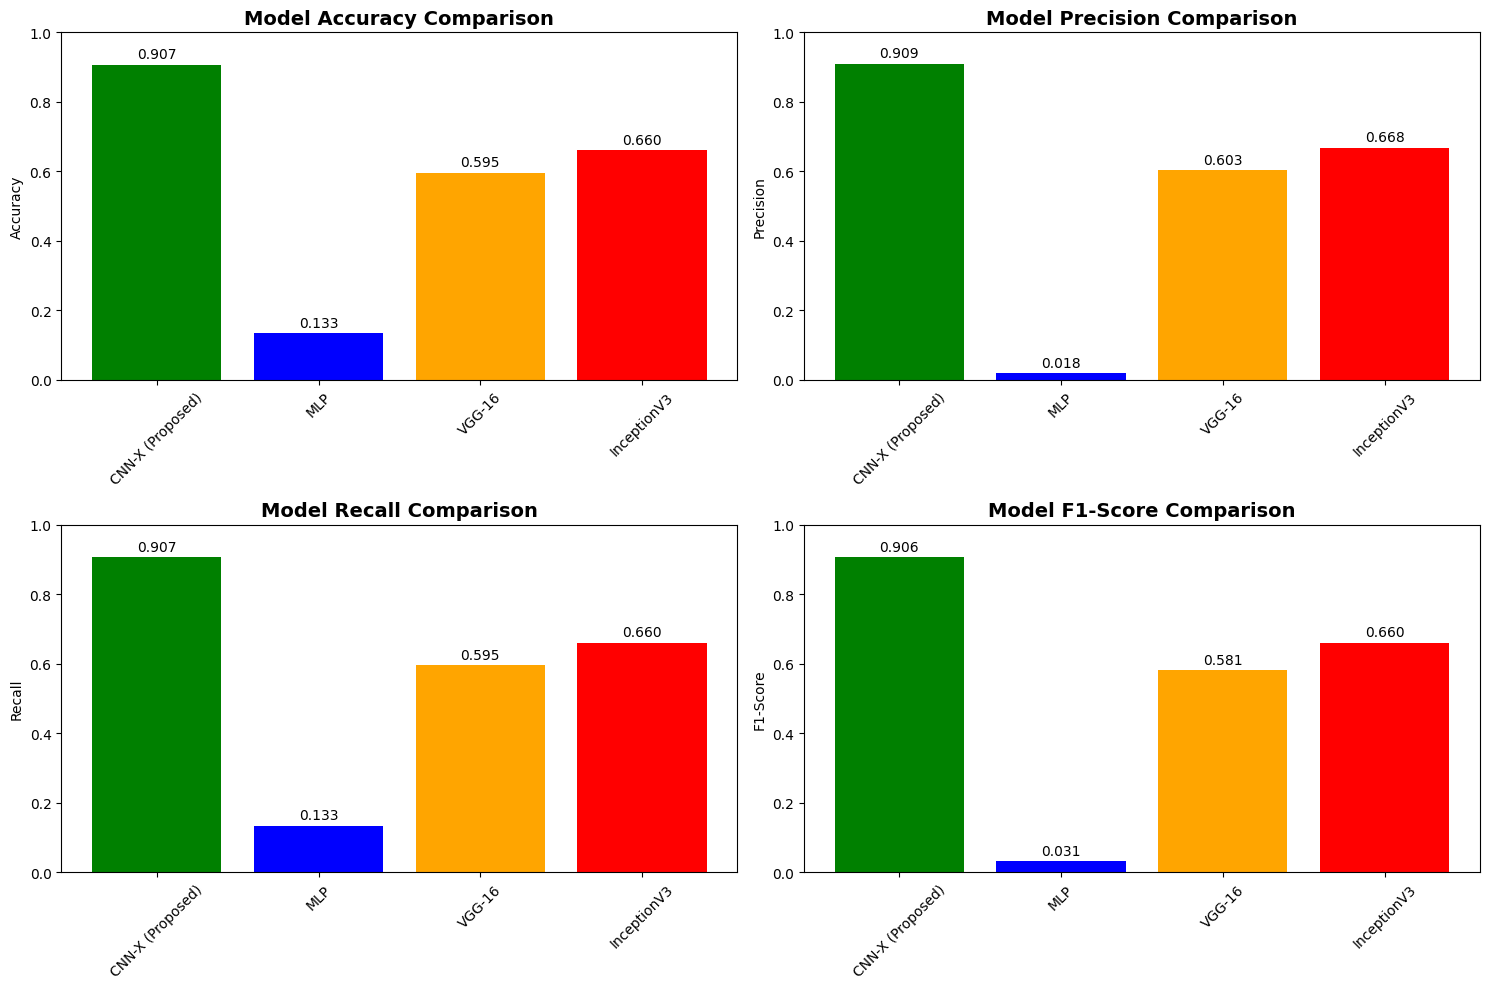

In [7]:
def plot_comparison_results(results):
    """绘制模型对比结果"""
    # 提取指标数据
    model_names = list(results.keys())
    accuracies = [results[name]['test_accuracy'] for name in model_names]
    precisions = [results[name]['precision'] for name in model_names]
    recalls = [results[name]['recall'] for name in model_names]
    f1_scores = [results[name]['f1_score'] for name in model_names]
    
    # 创建对比图表
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
    
    # 准确率对比
    bars1 = ax1.bar(model_names, accuracies, color=['green', 'blue', 'orange', 'red'])
    ax1.set_title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Accuracy')
    ax1.set_ylim(0, 1)
    ax1.tick_params(axis='x', rotation=45)
    # 在柱子上添加数值
    for bar in bars1:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # 精确率对比
    bars2 = ax2.bar(model_names, precisions, color=['green', 'blue', 'orange', 'red'])
    ax2.set_title('Model Precision Comparison', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Precision')
    ax2.set_ylim(0, 1)
    ax2.tick_params(axis='x', rotation=45)
    for bar in bars2:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # 召回率对比
    bars3 = ax3.bar(model_names, recalls, color=['green', 'blue', 'orange', 'red'])
    ax3.set_title('Model Recall Comparison', fontsize=14, fontweight='bold')
    ax3.set_ylabel('Recall')
    ax3.set_ylim(0, 1)
    ax3.tick_params(axis='x', rotation=45)
    for bar in bars3:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    # F1分数对比
    bars4 = ax4.bar(model_names, f1_scores, color=['green', 'blue', 'orange', 'red'])
    ax4.set_title('Model F1-Score Comparison', fontsize=14, fontweight='bold')
    ax4.set_ylabel('F1-Score')
    ax4.set_ylim(0, 1)
    ax4.tick_params(axis='x', rotation=45)
    for bar in bars4:
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    return fig

# 绘制对比结果
comparison_fig = plot_comparison_results(results)

In [8]:
def create_comparison_table(results):
    """创建详细的对比表格"""
    # 准备数据
    comparison_data = []
    for name, result in results.items():
        comparison_data.append({
            'Model': name,
            'Accuracy': f"{result['test_accuracy']:.4f}",
            'Precision': f"{result['precision']:.4f}",
            'Recall': f"{result['recall']:.4f}",
            'F1-Score': f"{result['f1_score']:.4f}"
        })
    
    # 创建DataFrame
    df_comparison = pd.DataFrame(comparison_data)
    
    # 按准确率排序
    df_comparison = df_comparison.sort_values('Accuracy', ascending=False)
    
    # 显示表格
    print("\n" + "="*70)
    print("MODEL COMPARISON RESULTS")
    print("="*70)
    print(df_comparison.to_string(index=False))
    
    # 与论文结果的对比
    print("\n" + "="*70)
    print("COMPARISON WITH PAPER RESULTS")
    print("="*70)
    paper_results = {
        'CNN-X (Paper)': {'Accuracy': 0.8299, 'Precision': 0.82, 'Recall': 0.82, 'F1-Score': 0.82},
        'VGG-16 (Paper)': {'Accuracy': 0.6493, 'Precision': 0.69, 'Recall': 0.64, 'F1-Score': 0.65},
        'InceptionV3 (Paper)': {'Accuracy': 0.4792, 'Precision': 0.45, 'Recall': 0.46, 'F1-Score': 0.43},
        'MLP (Paper)': {'Accuracy': 0.7500, 'Precision': 0.71, 'Recall': 0.69, 'F1-Score': 0.70}
    }
    
    comparison_with_paper = []
    for name in results.keys():
        paper_name = name + " (Paper)"
        if paper_name in paper_results:
            our_acc = float(results[name]['test_accuracy'])
            paper_acc = paper_results[paper_name]['Accuracy']
            diff = our_acc - paper_acc
            comparison_with_paper.append({
                'Model': name,
                'Our Accuracy': f"{our_acc:.4f}",
                'Paper Accuracy': f"{paper_acc:.4f}",
                'Difference': f"{diff:+.4f}"
            })
    
    df_paper_comparison = pd.DataFrame(comparison_with_paper)
    print(df_paper_comparison.to_string(index=False))
    
    return df_comparison, df_paper_comparison

# 创建对比表格
df_comparison, df_paper_comparison = create_comparison_table(results)


MODEL COMPARISON RESULTS
           Model Accuracy Precision Recall F1-Score
CNN-X (Proposed)   0.9072    0.9091 0.9072   0.9065
     InceptionV3   0.6602    0.6680 0.6602   0.6602
          VGG-16   0.5954    0.6035 0.5954   0.5810
             MLP   0.1331    0.0177 0.1331   0.0313

COMPARISON WITH PAPER RESULTS
      Model Our Accuracy Paper Accuracy Difference
        MLP       0.1331         0.7500    -0.6169
     VGG-16       0.5954         0.6493    -0.0539
InceptionV3       0.6602         0.4792    +0.1810


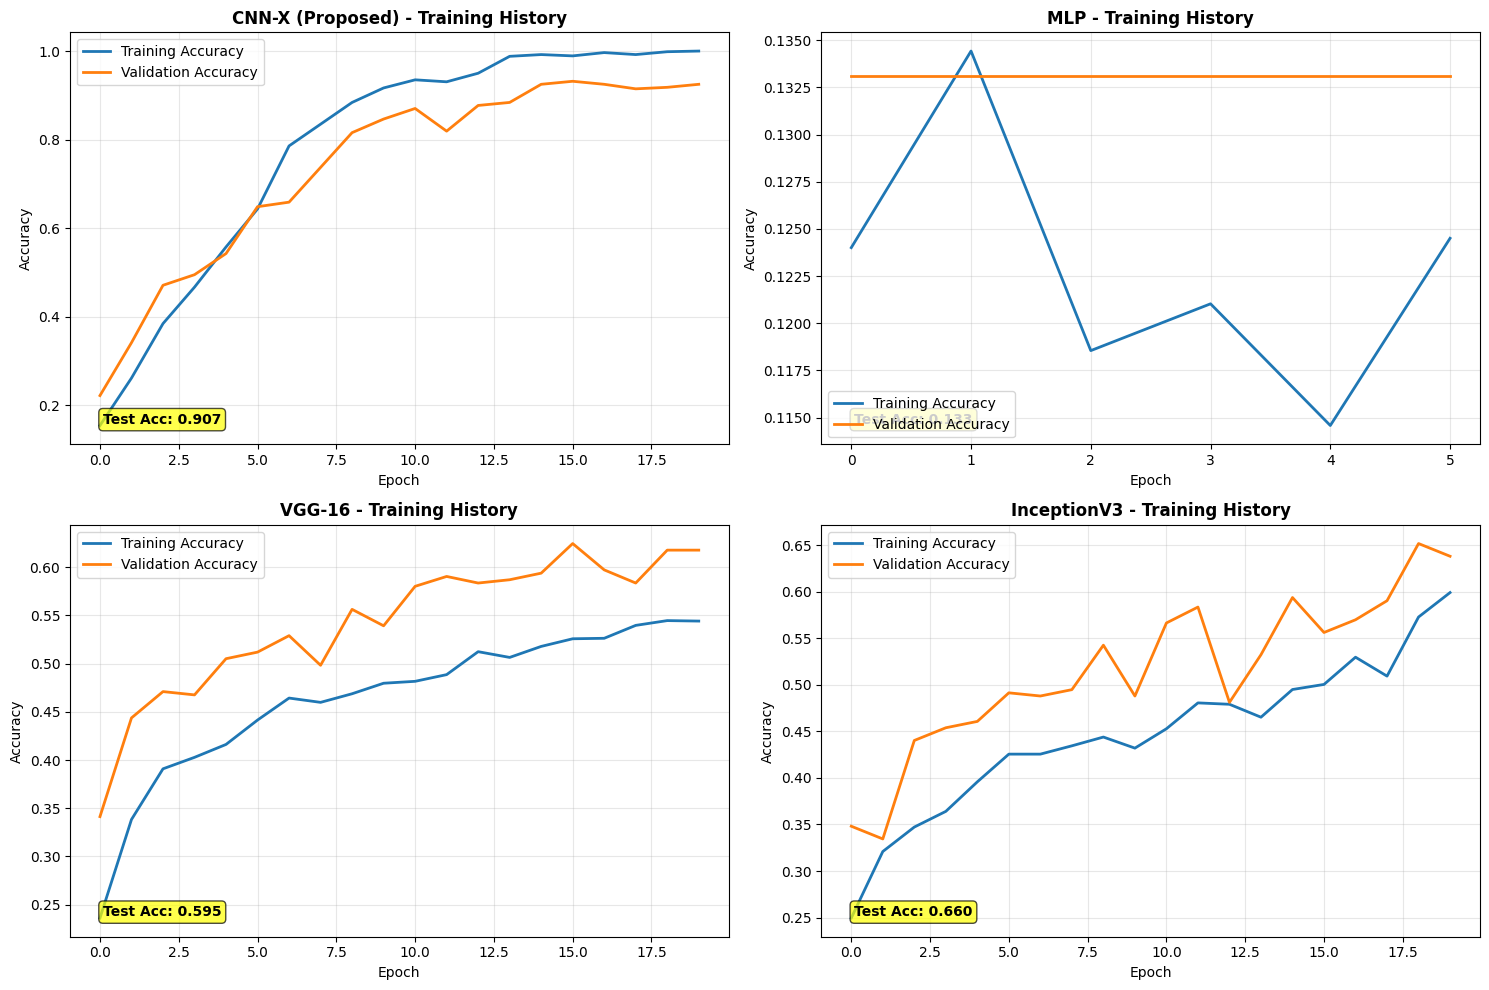

In [9]:
def plot_training_history(results):
    """绘制所有模型的训练历史"""
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    axes = axes.ravel()
    
    for idx, (name, result) in enumerate(results.items()):
        history = result['history']
        
        # 准确率
        axes[idx].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
        axes[idx].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
        axes[idx].set_title(f'{name} - Training History', fontweight='bold')
        axes[idx].set_xlabel('Epoch')
        axes[idx].set_ylabel('Accuracy')
        axes[idx].legend()
        axes[idx].grid(True, alpha=0.3)
        
        # 在图中添加最终测试准确率
        test_acc = result['test_accuracy']
        axes[idx].text(0.05, 0.05, f'Test Acc: {test_acc:.3f}', 
                      transform=axes[idx].transAxes, fontweight='bold',
                      bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))
    
    plt.tight_layout()
    plt.show()

# 绘制训练历史
plot_training_history(results)

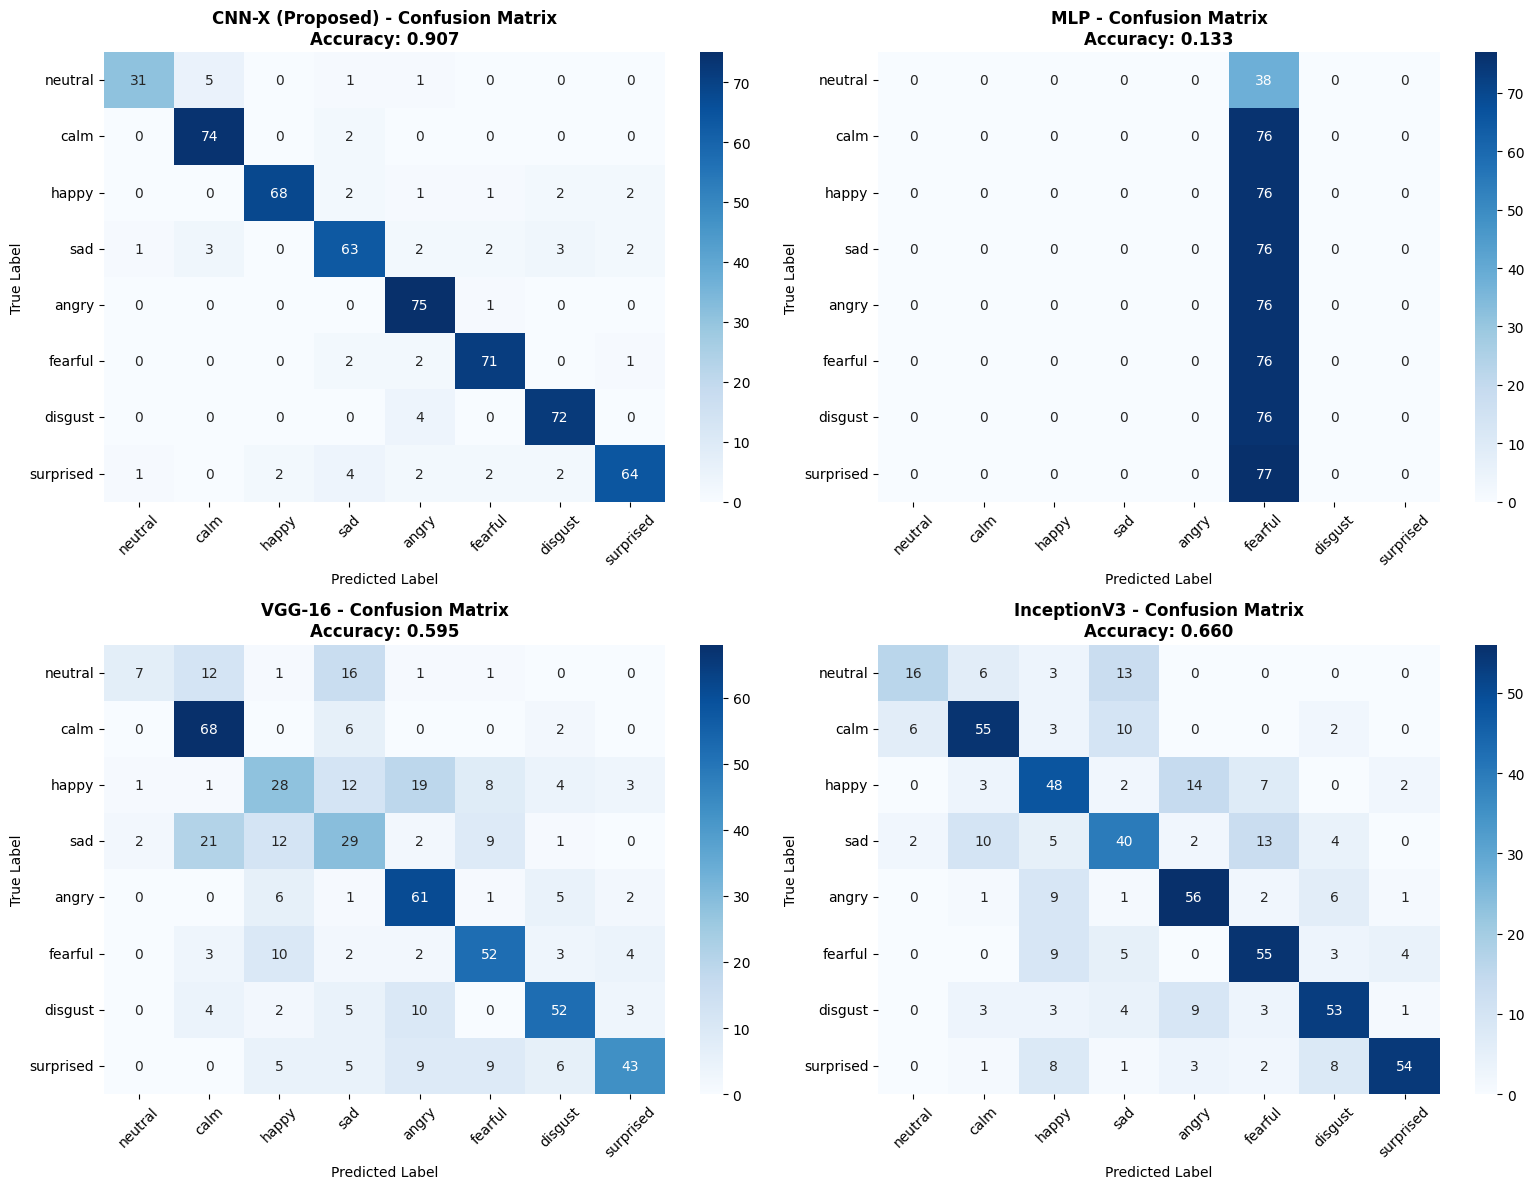

In [10]:
def plot_confusion_matrices(results, y_test, class_names):
    """绘制所有模型的混淆矩阵"""
    n_models = len(results)
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.ravel()
    
    emotion_labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
    
    for idx, (name, result) in enumerate(results.items()):
        y_pred = result['y_pred']
        cm = confusion_matrix(y_test, y_pred)
        
        # 绘制热力图
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                   xticklabels=emotion_labels,
                   yticklabels=emotion_labels,
                   ax=axes[idx])
        axes[idx].set_title(f'{name} - Confusion Matrix\nAccuracy: {result["test_accuracy"]:.3f}', 
                           fontweight='bold')
        axes[idx].set_xlabel('Predicted Label')
        axes[idx].set_ylabel('True Label')
        plt.setp(axes[idx].get_xticklabels(), rotation=45)
        plt.setp(axes[idx].get_yticklabels(), rotation=0)
    
    # 隐藏多余的子图
    for idx in range(n_models, 4):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    plt.show()

# 绘制混淆矩阵
emotion_labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
plot_confusion_matrices(results, y_test, emotion_labels)

In [11]:
def performance_summary(results):
    """生成性能总结报告"""
    print("\n" + "="*80)
    print("FINAL PERFORMANCE SUMMARY")
    print("="*80)
    
    best_model = max(results.items(), key=lambda x: x[1]['test_accuracy'])
    worst_model = min(results.items(), key=lambda x: x[1]['test_accuracy'])
    
    print(f"📊 Total Models Evaluated: {len(results)}")
    print(f"🏆 Best Model: {best_model[0]} (Accuracy: {best_model[1]['test_accuracy']:.4f})")
    print(f"📉 Worst Model: {worst_model[0]} (Accuracy: {worst_model[1]['test_accuracy']:.4f})")
    
    # 计算平均性能
    avg_accuracy = np.mean([result['test_accuracy'] for result in results.values()])
    print(f"📈 Average Accuracy: {avg_accuracy:.4f}")
    
    print("\n🔍 Key Observations:")
    for name, result in results.items():
        improvement = result['test_accuracy'] - avg_accuracy
        symbol = "↑" if improvement > 0 else "↓"
        print(f"   • {name}: {result['test_accuracy']:.4f} ({symbol}{abs(improvement):.4f} from average)")
    
    return best_model, worst_model

# 生成总结报告
best_model, worst_model = performance_summary(results)


FINAL PERFORMANCE SUMMARY
📊 Total Models Evaluated: 4
🏆 Best Model: CNN-X (Proposed) (Accuracy: 0.9072)
📉 Worst Model: MLP (Accuracy: 0.1331)
📈 Average Accuracy: 0.5740

🔍 Key Observations:
   • CNN-X (Proposed): 0.9072 (↑0.3332 from average)
   • MLP: 0.1331 (↓0.4409 from average)
   • VGG-16: 0.5954 (↑0.0215 from average)
   • InceptionV3: 0.6602 (↑0.0863 from average)
